# Lab 00: How to check your setup

**CPU | API key: `OPENAI_API_KEY` for Part E only | Follows: Day 1 step 1.2 (slides 10–13) and the Day 2 versions slide (D2-M01-11)**

## Goal

Prove the four things every later lab assumes: the pinned packages are installed, the data files are unchanged, the
Chinook Ops API starts, and your key reaches the chat model. Each part ends with a check that passes or fails, so a
broken install shows up here and not halfway through Lab 06. The moments that teach it: a copy of the handbook with
one added line break reads the same and has a completely different hash; and the model answers a question about
Chinook's download links confidently and wrongly, because it has never seen the shop's rules.

## What you will learn

- How every lab in this repository starts, on Colab or on your own machine, and what its first two cells do.
- How to check that the installed packages match their pins, and why one pin (`langgraph`) is held back.
- How to prove a data file is unchanged with a SHA-256 hash.
- What the Chinook database holds, with SQL row counts and two customers the later labs use.
- How to start the shop's Ops API and call it over HTTP (needed from Lab 07).
- How to make one model call with your key, read its token usage and price it.

| Part | What it checks | Key needed? |
|---|---|---|
| A | Python and the pinned package versions | no |
| B | The SHA-256 hash of every data file | no |
| C | Row counts and two customers in the Chinook database | no |
| D | The Ops API starts and answers (the Day 2 labs, 07–13, need it) | no |
| E | One call to the chat model, with its token usage | yes |

## The first two cells

Every lab in this repository opens with the same two cells.

**Setup** finds the repository folder. On Colab it first copies the repository into the session with a shallow
`git clone` (only the latest version of each file) and installs the packages in `requirements.txt`. On your own
machine you ran `uv sync` once, so the cell installs nothing.

**Config** reads the model names from `models.env` in the repository folder, the one file that sets them for every lab.
If you put the same name in your `.env` file or in an environment variable, your value wins. Then it looks for your
OpenAI key: in the environment, in `.env`, then in Colab Secrets. It prints where it found the key, never the key.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


On Colab the install takes about a minute. Colab already has most of these packages; the install adds the missing
ones and upgrades `openai` from the 2.x series to 3.24.0. pip ends with *"you may need to restart the kernel"* after
every install. Run as the first cell of a fresh session, no restart is needed, because nothing has loaded the old
`openai` yet.

⚠️ If you ran other cells first, the old `openai` may already be loaded, and Part E then fails with
`ImportError: cannot import name ... from 'openai...'`. Use **Runtime → Restart session** and run the notebook from
the top; the clone is skipped the second time.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`models.env` names one chat model for the copilot and the judge (`gpt-4o-mini` when we ran these labs on 10 Oct 2026) and
`text-embedding-3-small` for search. `REASONING_EFFORT` is empty because `gpt-4o-mini` has no reasoning-effort setting;
a reasoning model such as `gpt-6-luna` has one, and Lab 01 shows the difference. No notebook names a model in its code.
To change a model for every lab, change `models.env` once.

If the key line says `not found`, Parts A to D still run. Add the key before Part E (see the table at the end of
this notebook).

The map below shows which file or service each part of this lab touches.

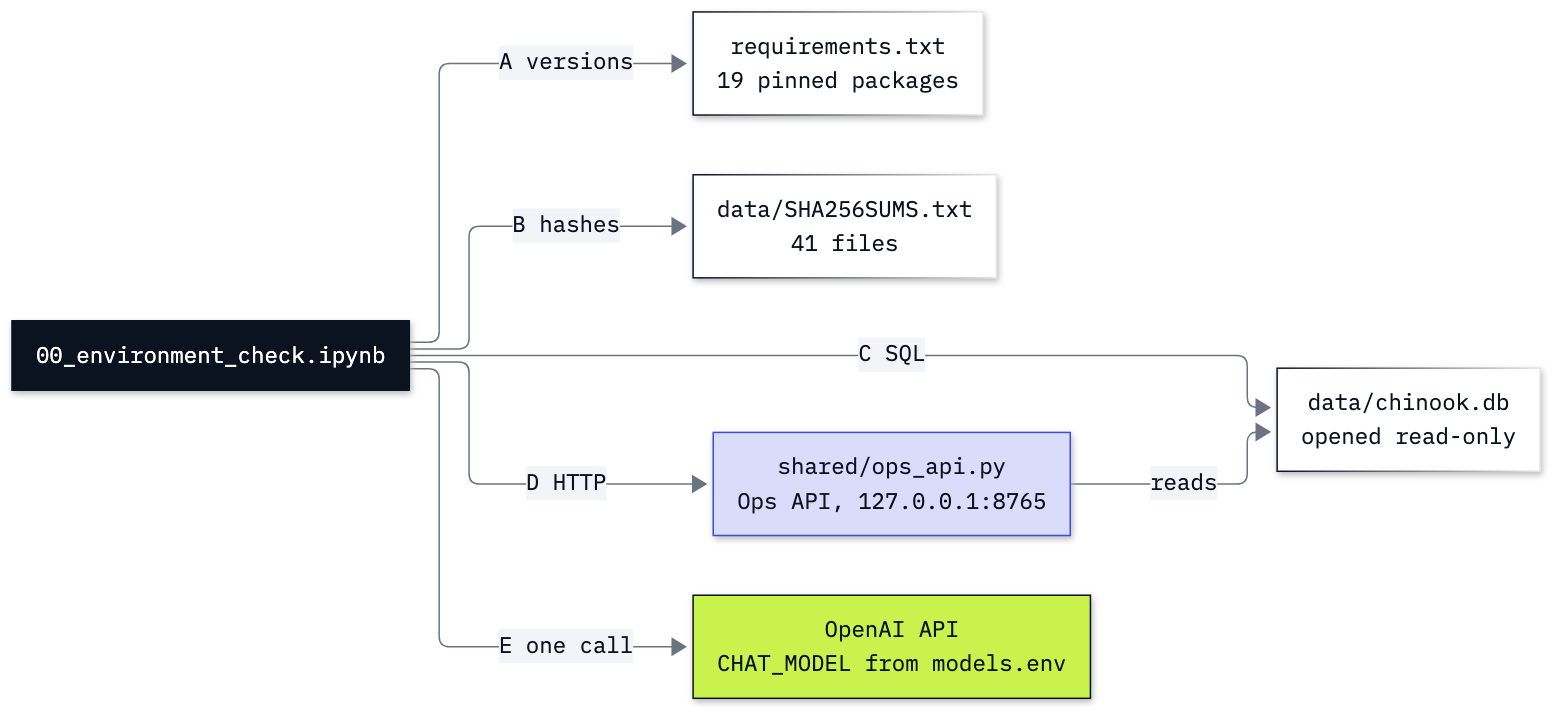

In [3]:
from IPython.display import Image
Image(filename=ROOT / "00_Environment_Check" / "resources" / "lab00_checks.png", width=760)

---

## Part A: Python and package versions

Every saved output in these labs came from exact package versions, pinned in `requirements.txt`. A different version
is a different library: a later lab's output, warning or error might not match what the notebook shows.

First, the Python version. Colab runs Python 3.13, and the local setup asks `uv` for 3.13 too, so a value that moves
between versions moves for everyone.

In [4]:
import platform

print("Python  ", platform.python_version())
print("Platform", "Colab" if IN_COLAB else platform.system())

Python   3.13.5
Platform Darwin


Next, the pins. `requirements.txt` holds one `name==version` line per package. We read it into a dictionary rather
than typing the list again, so this check always tests the file that installed the packages.

In [5]:
pins = {}
for line in (ROOT / "requirements.txt").read_text().splitlines():
    if line and not line.startswith("#"):
        name, pinned = line.split("==")
        pins[name] = pinned

print(len(pins), "pinned packages")
print(list(pins.items())[:3])

20 pinned packages
[('langchain', '1.4.3'), ('langchain-core', '1.6.6'), ('langchain-openai', '1.6.7')]


Now compare each pin with what is installed. `importlib.metadata.version` asks the environment the notebook runs in,
which is the one that matters: a terminal can show a different Python from the notebook's kernel.

In [6]:
from importlib.metadata import version, PackageNotFoundError

mismatches = 0
for name, pinned in pins.items():
    try:
        installed = version(name)
    except PackageNotFoundError:
        installed = "missing"
    if installed != pinned:
        mismatches += 1
    status = "ok" if installed == pinned else "DIFFERENT"
    print(f"{name:28}{installed:10} pin {pinned:10} {status}")

print("\nPackages that differ from their pin:", mismatches)

langchain                   1.4.3      pin 1.4.3      ok
langchain-core              1.6.6      pin 1.6.6      ok
langchain-openai            1.6.7      pin 1.6.7      ok
langchain-classic           1.0.8      pin 1.0.8      ok
langchain-text-splitters    1.1.3      pin 1.1.3      ok
langgraph                   1.2.12     pin 1.2.12     ok
langgraph-checkpoint        4.2.0      pin 4.2.0      ok
langgraph-checkpoint-sqlite 3.1.1      pin 3.1.1      ok
openai                      3.24.0     pin 3.24.0     ok
tiktoken                    0.14.0     pin 0.14.0     ok
faiss-cpu                   1.15.1     pin 1.15.1     ok
gradio                      6.29.0     pin 6.29.0     ok
huggingface-hub             1.33.0     pin 1.33.0     ok
fastapi                     0.141.1    pin 0.141.1    ok
uvicorn                     0.54.0     pin 0.54.0     ok
httpx                       0.28.1     pin 0.28.1     ok
pydantic                    2.13.5     pin 2.13.5     ok
python-dotenv               1.2

Look at `langgraph`: it shows 1.2.12, although 1.2.14 was on PyPI when this lab was built. Version 1.2.13 changed
how a paused run reports an approval it has already received, and the labs that pause for approval (08, 12 and 13)
were written on 1.2.12. Do not upgrade it to remove a warning.

`langchain-classic` is there only for Lab 01's look at the old `LLMChain`, `langgraph-checkpoint-sqlite` saves a
conversation to a file in Lab 03, and `matplotlib` draws the charts from Lab 03 on.

### Checkpoint A

| You should see | Value from our run |
|---|---|
| Python | 3.13.x |
| Packages that differ from their pin | 0 (20 packages) |
| langgraph | 1.2.12 |

---

## Part B: Check the data files

The labs read the shop's policies and tickets, the support handbook, the Chinook database, a prebuilt search index
and five evaluation cases from `data/`. Many checkpoints depend on the exact text: the handbook index's chunks, Lab 06's
retrieval scores. A SHA-256 hash is a 64-character fingerprint of a file's bytes. Change one byte and the fingerprint
changes completely, so matching hashes prove the files are unchanged.

One file in the corpus, `ticket_16_overpayment_note.md`, contains a planted instruction aimed at a summariser. It is
there on purpose for the prompt-injection tests in Labs 11, 12 and 13. Treat it as data.

First, what is in `data/`.

In [7]:
DATA = ROOT / "data"

for path in sorted(DATA.iterdir()):
    if path.is_dir():
        print(f"{path.name + '/':16}folder, {len(list(path.iterdir()))} item(s)")
    elif not path.name.startswith("."):
        print(f"{path.name:16}{path.stat().st_size:,} bytes")

README.md       4,520 bytes
SHA256SUMS.txt  3,991 bytes
chinook.db      884,736 bytes
corpus/         folder, 36 item(s)
evalset.json    4,645 bytes
handbook/       folder, 1 item(s)
index/          folder, 2 item(s)


Hash one file first: the support handbook. `hashlib.sha256` takes the file's bytes and `hexdigest()` writes the result
as 64 hexadecimal characters.

In [8]:
import hashlib

handbook = DATA / "handbook" / "support_handbook.md"
print(hashlib.sha256(handbook.read_bytes()).hexdigest())

d27874b858aecefed0116e5b520d614592c408863dc3085ddd73671e34effaea


`data/README.md` records the handbook as `d27874b8…effaea`. Compare the first and last few characters
with the output above.

Checking 41 files by eye would be slow. `data/SHA256SUMS.txt` lists the expected hash of every file, one per line,
in the format the `sha256sum` and `shasum` commands use: the hash, two spaces, the path.

In [9]:
sums = (DATA / "SHA256SUMS.txt").read_text().splitlines()
print(len(sums), "lines")
for line in sums[:3]:
    print(line)

41 lines
d6c11e2ccda2a36883af57f031f76fbd55e247f3be1710c4c8aaa72ec06a18cb  chinook.db
9c516e87bce207d0ad0beccc97c13d4b119ad4bcca37f342a9ff771365ddbda1  corpus/policy_accounts.md
a3b23d42220682d9c96fe316f8d0c1b82e22151996847c502b4e33fbf246d3bc  corpus/policy_cancellations.md


Now hash every listed file and count the matches.

In [10]:
matched, changed = 0, []
for line in sums:
    expected, name = line.split("  ")
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    if actual == expected:
        matched += 1
    else:
        changed.append(name)

print(f"{matched} of {len(sums)} files match")
print("Changed:", changed or "none")

41 of 41 files match
Changed: none


### Add one line break to a copy and hash it

Text editors often add a line break at the end of a file when you save it. Predict: if we add one line break to a
copy of the handbook, will the copy still read the same, and will its hash still match?

We change a copy in a temporary folder, never the real file.

In [11]:
import tempfile

copy = Path(tempfile.mkdtemp()) / "support_handbook.md"
copy.write_bytes(handbook.read_bytes() + b"\n")

print("Same words:  ", handbook.read_text().split() == copy.read_text().split())
print("Original hash", hashlib.sha256(handbook.read_bytes()).hexdigest()[:16], "...")
print("Copy hash    ", hashlib.sha256(copy.read_bytes()).hexdigest()[:16], "...")

Same words:   True
Original hash d27874b858aecefe ...
Copy hash     812f46c1d9bf66a1 ...


The words are identical and the hash is completely different. Opening a data file and saving it can break a
checkpoint in a later lab, which is why the labs only read `data/`. If a file ever fails this check, get it back
from the repository (see the troubleshooting table).

### Checkpoint B

| You should see | Value from our run |
|---|---|
| Files that match | 41 of 41 (36 corpus files, the handbook, `chinook.db`, the two index files, `evalset.json`) |
| Handbook hash | `d27874b858aecefed0116e5b520d614592c408863dc3085ddd73671e34effaea` |
| `chinook.db` hash | `d6c11e2ccda2a36883af57f031f76fbd55e247f3be1710c4c8aaa72ec06a18cb` |
| The edited copy | same words, a different hash |

---

## Part C: Query the Chinook database

Chinook is a sample database of a fictional online music shop: customers, employees, invoices and the tracks on
them. In these labs it is the shop's back office. The copilot never opens it directly; on Day 2 it asks the Ops API
(Part D), which reads it.

`sqlite3` ships with Python. The `?mode=ro` part of the address opens the file read-only, so nothing in this notebook
can change it.

In [12]:
import sqlite3

db = sqlite3.connect(f"file:{DATA / 'chinook.db'}?mode=ro", uri=True)
print(db.execute("SELECT COUNT(*) FROM customers").fetchone())

(59,)


`fetchone()` returns one row as a tuple, here with one value: 59 customers. Now the six tables the labs use.

In [13]:
counts = {}
for table in ("customers", "invoices", "invoice_items", "employees", "tracks", "albums"):
    counts[table] = db.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
print(counts)

{'customers': 59, 'invoices': 412, 'invoice_items': 2240, 'employees': 8, 'tracks': 3503, 'albums': 347}


Two customers come back in Labs 03, 07 and 08: Helena Holý and Puja Srivastava. This query counts each one's
invoices, adds up what they spent and names their support rep, the employee who
looks after them.

In [14]:
QUERY = """
SELECT c.CustomerId, c.FirstName || ' ' || c.LastName AS name,
       COUNT(i.InvoiceId) AS invoices, ROUND(SUM(i.Total), 2) AS total,
       e.FirstName || ' ' || e.LastName AS support_rep
FROM customers c
JOIN invoices i  ON i.CustomerId = c.CustomerId
JOIN employees e ON e.EmployeeId = c.SupportRepId
WHERE c.FirstName IN ('Helena', 'Puja')
GROUP BY c.CustomerId
"""
for row in db.execute(QUERY):
    print(row)

(6, 'Helena Holý', 7, 49.62, 'Steve Johnson')
(59, 'Puja Srivastava', 6, 36.64, 'Jane Peacock')


The connection is read-only. This update would move Helena to another country, and SQLite refuses it.

In [15]:
try:
    db.execute("UPDATE customers SET Country = 'Nowhere' WHERE CustomerId = 6")
except sqlite3.OperationalError as error:
    print("Refused:", error)

Refused: attempt to write a readonly database


The Ops API opens the database the same way, so the copilot cannot change a customer's record either. Its one
write, a refund request on Day 2, goes to a separate file.

### Checkpoint C

| You should see | Value from our run |
|---|---|
| Row counts | customers 59, invoices 412, invoice_items 2240, employees 8, tracks 3503, albums 347 |
| Helena Holý | customer 6, 7 invoices, 49.62, Steve Johnson |
| Puja Srivastava | customer 59, 6 invoices, 36.64, Jane Peacock |
| The update | refused: `attempt to write a readonly database` |

---

## Part D: Start the Ops API

The Ops API is a small web service, written with FastAPI for these labs, that the copilot acts through on Day 2:
find a customer, list their invoices, read one invoice, file a refund request. You call it in the labs; you do not
write it. Its code is in `shared/ops_api.py`.

⚠️ The Day 2 labs (07 to 13) need this part. If it fails and you only have Day 1 labs ahead, you can continue and
come back to it.

`start_ops_api()` runs the service inside this notebook, in a background thread, on `127.0.0.1` (your own machine or
your Colab session, not the internet) at port 8765.

In [16]:
from shared.ops_api import start_ops_api

server = start_ops_api(port=8765)

Ops API started at http://127.0.0.1:8765


The Ops API answers `GET /health` when it is up, as most web services do. We call it with `httpx`, the HTTP client the
copilot's tools use on Day 2.

In [17]:
import httpx

API = "http://127.0.0.1:8765"
response = httpx.get(f"{API}/health")
print(response.status_code, response.json())

200 {'status': 'ok'}


Status 200 means the request worked. Now a real question: find the customer called Helena.

In [18]:
response = httpx.get(f"{API}/customers", params={"name": "Helena"})
print(response.status_code)
print(response.json())

200
[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic', 'support_rep': 'Steve Johnson'}]


The API returns a list, because a name can match more than one customer, with only four fields per customer. On
Day 2 the copilot calls this endpoint to find who a ticket is about.

Now ask the API for Helena's invoices and compare its numbers with the SQL query in Part C.

In [19]:
helena = httpx.get(f"{API}/customers/6/invoices").json()
print(helena["count"], "invoices,", helena["total"], "in total, rep", helena["support_rep"])

7 invoices, 49.62 in total, rep Steve Johnson


The same 7 invoices, 49.62 and Steve Johnson that SQL gave in Part C.

What happens if you run the start cell twice? The port is taken by the first server,
so a second server could not start there. `start_ops_api()` first asks `/health`; if a server already answers, it
reuses that one.

In [20]:
second = start_ops_api(port=8765)
print("New server started:", second is not None)

Ops API already running at http://127.0.0.1:8765: reusing it
New server started: False


This lab does not need the service any more, so we stop it. Each Day 2 lab starts it again in its own setup.

In [21]:
if server:
    server.should_exit = True

### Checkpoint D

| You should see | Value from our run |
|---|---|
| `/health` | `200 {'status': 'ok'}` |
| `/customers?name=Helena` | `200`, one record: customer_id 6, Helena Holý, Czech Republic, Steve Johnson |
| Helena's invoices | 7 invoices, 49.62, rep Steve Johnson (the same as Part C) |
| Second start | `Ops API already running ... reusing it`, no new server |

---

## Part E: One model call, recorded

⚠️ This part sends one request to OpenAI with your key. It costs a small fraction of a US cent. Without a key, its
first cell stops with `OpenAIError: Missing credentials`, and every cell after it, including the record at the end,
fails with `NameError`, because the client and the reply were never made. Parts A to D are not affected. Add the key
(see the troubleshooting table), run the config cell again, then run this part from its first cell.

`chat_model()` in `shared/settings.py` builds a LangChain `ChatOpenAI` client for `CHAT_MODEL` that talks to OpenAI's
Responses API. Lab 01 builds the same client by hand and explains each argument; here we only check that it works.

In [22]:
from shared.settings import chat_model

model = chat_model(settings)
print(model.model_name, "| Responses API:", model.use_responses_api)

gpt-4o-mini | Responses API: True


The question is one a rep might ask on their first day: *How long does a digital download link last?* Chinook's
policy (`policy_digital_downloads.md`) says a download is available for 90 days after purchase, and a
replacement link lasts 7 days.

Predict before you run: the model has not seen Chinook's policy. Will its answer match it?

In [23]:
import time

question = "How long does a digital download link last?"
start = time.perf_counter()
reply = model.invoke([
    ("system", "You help Chinook support reps. Be brief."),
    ("user", question),
])
seconds = time.perf_counter() - start
print(reply.text)

A digital download link typically lasts for 7 to 30 days, depending on the provider. Check the specific terms for your purchase for exact details.


When we ran it (10 Oct 2026), `gpt-4o-mini` answered that a link *typically lasts for 7 to 30 days, depending on the
provider*. That is a reasonable general answer and wrong for Chinook, which gives 90 days. The 7 in it is a
coincidence: Chinook's 7 days is for a replacement link. A reference run with `gpt-6-luna` on 5 Oct 2026 said
*24 hours*, also wrong for Chinook. If `models.env` names another model, expect another wrong answer.
A model only knows the shop's rules when we give them to it. That is what the copilot's tools (Lab 01) and the
handbook search (Lab 06) are for.

Every reply also reports how many tokens it used. Tokens are the pieces of text a model reads and writes, and you pay
per token.

In [24]:
usage = reply.usage_metadata
print(usage)
print("Model:", reply.response_metadata["model_name"], "| seconds:", round(seconds, 2))

{'input_tokens': 30, 'output_tokens': 31, 'total_tokens': 61, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 0}}
Model: gpt-4o-mini-2024-07-18 | seconds: 1.51


`input_tokens` counts the system message and the question; `output_tokens` counts the reply. A reasoning model also
counts the hidden reasoning it writes before it answers: the `gpt-6-luna` reference run (5 Oct 2026) used 207 output
tokens, 188 of them reasoning. `gpt-4o-mini` does not reason, so its reasoning count is 0 and its output tokens are
only the words you see.

The prices per million tokens are in `models.env`, so the cost of this call is two multiplications.

In [25]:
cost = (usage["input_tokens"] * float(settings["CHAT_PRICE_INPUT"])
        + usage["output_tokens"] * float(settings["CHAT_PRICE_OUTPUT"])) / 1_000_000
print(f"This call cost about ${cost:.6f}")

This call cost about $0.000023


### Checkpoint E

The wording and the counts change from run to run, so check the facts.

| You should see | Value from our run (`gpt-4o-mini`, 10 Oct 2026) |
|---|---|
| The reply | text that does not state Chinook's 90 days (the model has no policy) |
| `usage_metadata` | `input_tokens` 30, `output_tokens` 31 in our run (yours will be close), reasoning 0 |
| Model name | `gpt-4o-mini-2024-07-18` (the dated snapshot behind `gpt-4o-mini`) |
| Cost | about $0.000023 in our run: well under a tenth of a US cent |

---

## Your record

Later labs compare their numbers with runs on other machines, so keep a short record of this one: the date, where it
ran, the Python version, and the result of each check. Copy the output into your notes.

In [26]:
from datetime import date

checks = {
    "A  Python 3.13 and pinned packages": platform.python_version().startswith("3.13") and mismatches == 0,
    "B  data hashes": not changed,
    "C  Chinook rows": counts["customers"] == 59 and counts["invoices"] == 412,
    "D  Ops API answers": helena["count"] == 7 and helena["total"] == 49.62,
    "E  one model call": usage["output_tokens"] > 0,
}

print("Run on", date.today().isoformat(), "|", "Colab" if IN_COLAB else platform.system(),
      "| Python", platform.python_version(), "|", reply.response_metadata["model_name"])
for name, passed in checks.items():
    print("✅" if passed else "❌", name)

Run on 2026-10-10 | Darwin | Python 3.13.5 | gpt-4o-mini-2024-07-18
✅ A  Python 3.13 and pinned packages
✅ B  data hashes
✅ C  Chinook rows
✅ D  Ops API answers
✅ E  one model call


## What you can do now

- Open any lab in this repository on Colab or locally; its first two cells are the ones you ran here.
- Tell whether an environment matches the repository's pins, and say why `langgraph` stays at 1.2.12.
- Prove with a SHA-256 hash that a data file is unchanged since its hash was recorded.
- Query Chinook with SQL and find Helena Holý and Puja Srivastava, the two customers the later labs use.
- Start the Ops API and call it over HTTP.
- Make a model call with your key, read its token usage and price it.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Part A shows a Python other than 3.13 (local) | the notebook runs on another kernel | choose the repository's `.venv` kernel; run `uv sync` in the repository folder first |
| A package shows `DIFFERENT` or `missing` | the setup cell did not run, or Colab still had an older version loaded | run the setup cell; on Colab use Runtime → Restart session, then run from the top |
| `ImportError: cannot import name ... from 'openai...'` (Colab) | the old `openai` was loaded before the install | Runtime → Restart session, then run from the top |
| `ModuleNotFoundError: No module named 'shared'` | the setup cell was skipped, or the notebook was opened outside the repository | run the setup cell first; locally, open the notebook from inside the repository folder |
| `StopIteration` in the setup cell (local) | the notebook is not inside the repository folder | open it from the cloned repository, where `models.env` sits |
| A data hash does not match | a file was opened and saved by an editor | locally, `git checkout -- data/<file>`; on Colab, delete the folder and run the setup cell again |
| `Ops API did not start on port 8765` | another program, not the Ops API, uses the port | restart the kernel; if it still fails, use `start_ops_api(port=8766)` and that port in `API` |
| The config cell says the key is `not found`, or Part E stops with `OpenAIError: Missing credentials` | no key in the environment, `.env` or Colab Secrets | Colab: add `OPENAI_API_KEY` under Secrets (key icon) and switch on notebook access; locally: put it in `.env`. Then run the config cell again |
| `AuthenticationError` in Part E | the key is wrong or was revoked | paste the key again; ask the instructor if it is a class key |
| `NotFoundError` naming the model | `CHAT_MODEL` is misspelt, or your account cannot use it | check `models.env` and any `CHAT_MODEL` line in `.env` |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor.

1. **Puja through the Ops API.** Find Puja's customer number with `/customers?name=Puja`, then read her invoices.
   Expected: customer 59 in India, rep Jane Peacock, 6 invoices, 36.64 in total, the same as the SQL in Part C.
2. **The largest invoice.** Write a SQL query that finds the invoice with the largest total and the customer it
   belongs to. Then read that invoice through the Ops API (`/invoices/<id>`) and compare it with `/invoices/9001`.
   Expected: invoice 404, 25.86, customer 6 (Helena), `"source": "chinook.db"`; invoice 9001 is 9.99 with
   `"source": "course fixture"`. The fixture invoices (9001 to 9003) exist only in the API's code, for ticket 14 and
   the refund labs; they are not in `chinook.db`.
3. **Override a model name without editing a file.** Set `os.environ["CHAT_MODEL"]` to a name that does not exist,
   load the settings again and make the Part E call. Then delete the variable and load the settings once more.
   Expected: the settings show your name; the call fails with a not-found error, status 404 (LangChain names it
   `OpenAIModelNotFoundError`; it is a kind of `openai.NotFoundError`), before any tokens are used;
   after the delete, `CHAT_MODEL` is `gpt-4o-mini` again.

## Resources

- [uv: working on projects](https://docs.astral.sh/uv/guides/projects/): `uv sync`, `.python-version` and the lock file
- [Python `hashlib`](https://docs.python.org/3/library/hashlib.html) and [`sqlite3`](https://docs.python.org/3/library/sqlite3.html): the two standard-library modules used in Parts B and C
- [SQLite URI filenames](https://www.sqlite.org/uri.html): what `?mode=ro` does
- [Chinook Database](https://github.com/lerocha/chinook-database): the sample database's origin and licence
- [FastAPI tutorial](https://fastapi.tiangolo.com/tutorial/) and [HTTPX quickstart](https://www.python-httpx.org/quickstart/): the service and the client in Part D
- [LangChain `ChatOpenAI`](https://docs.langchain.com/oss/python/integrations/chat/openai): the client in Part E, including the Responses API
- [OpenAI: gpt-4o-mini](https://developers.openai.com/api/docs/models/gpt-4o-mini): the model's prices and limits, the values in `models.env`